# 01. Tổng quan dữ liệu thô
Dự án dùng 6 bộ tin đăng bán bất động sản Việt Nam lấy từ Kaggle. Notebook này chỉ **đọc và mô tả** dữ liệu gốc để thấy mức độ "dơ" của từng nguồn, chưa sửa gì.

| Nguồn | Kaggle | Nội dung |
|---|---|---|
| 1 | yashdev01/vietnam-real-estates | Tin đăng toàn quốc 06–12/2025 |
| 2 | qmanhbeo/vietnamese-real-estate-listings-may-2024 | Tin đăng toàn quốc 04–09/2025 |
| 3 | ladcva/vietnam-housing-dataset-hanoi | Nhà ở Hà Nội 2020 |
| 4 | cresht2606/vietnam-real-estate-datasets-catalyst | Tin bán nhà batdongsan.vn 12/2025 |
| 5 | nguyentiennhan/vietnam-housing-dataset-2024 | Nhà ở toàn quốc 2024 |
| 6 | huytrngquc/hanoi-housing-price-2024 | Tin đăng Hà Nội 12/2024 |

In [1]:
import sys, os, re, time
sys.path.append('../src')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from xu_ly_chuoi import *

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 160)
pd.set_option('display.max_colwidth', 60)
sns.set_theme(style='whitegrid')
RAW = '../data/raw'

In [2]:
FILES = {
    1: 'nguon1_vietnam_real_estate_2025.csv',
    2: 'nguon2_vn_real_estate_apr_sep_2025.csv',
    3: 'nguon3_vn_housing_hanoi_2020.csv',
    4: 'nguon4_batdongsan_house_buying_2025.csv',
    5: 'nguon5_vietnam_housing_2024.csv',
    6: 'nguon6_hanoi_houseprice_2024.csv',
}
du_lieu = {}
for k, f in FILES.items():
    if k == 1:
        du_lieu[k] = pd.read_csv(os.path.join(RAW, f), usecols=lambda c: c != 'description', low_memory=False)
    else:
        du_lieu[k] = pd.read_csv(os.path.join(RAW, f), low_memory=False)

tong_quan = pd.DataFrame({
    'File': FILES,
    'Dung lượng (MB)': {k: round(os.path.getsize(os.path.join(RAW, f)) / 1e6, 1) for k, f in FILES.items()},
    'Số dòng': {k: len(d) for k, d in du_lieu.items()},
    'Số cột': {k: d.shape[1] + (1 if k == 1 else 0) for k, d in du_lieu.items()},
    'Tỉ lệ ô thiếu (%)': {k: round(d.isna().mean().mean() * 100, 1) for k, d in du_lieu.items()},
})
tong_quan.index.name = 'Nguồn'
print('Tổng số dòng thô của 6 nguồn:', f"{tong_quan['Số dòng'].sum():,}")
tong_quan

Tổng số dòng thô của 6 nguồn: 1,429,399


,File,Dung lượng (MB),Số dòng,Số cột,Tỉ lệ ô thiếu (%)
Nguồn,,,,,
1,nguon1_vietnam_real_estate_2025.csv,922.1,1000000,19,38.3
2,nguon2_vn_real_estate_apr_sep_2025.csv,220.1,236226,28,25.5
3,nguon3_vn_housing_hanoi_2020.csv,18.1,82497,13,17.2
4,nguon4_batdongsan_house_buying_2025.csv,17.5,66912,11,8.2
5,nguon5_vietnam_housing_2024.csv,3.5,30229,12,29.1
6,nguon6_hanoi_houseprice_2024.csv,4.7,13535,15,0.0


### Mỗi nguồn một cấu trúc cột khác nhau

In [3]:
for k, d in du_lieu.items():
    print(f'Nguồn {k}:', list(d.columns) + (['description'] if k == 1 else []))

Nguồn 1: ['name', 'property_type_name', 'province_name', 'district_name', 'ward_name', 'street_name', 'project_name', 'price', 'area', 'floor_count', 'frontage_width', 'house_depth', 'road_width', 'bedroom_count', 'bathroom_count', 'house_direction', 'balcony_direction', 'published_at', 'description']
Nguồn 2: ['Title', 'Price', 'Area', 'Location', 'Listing ID', 'Last Updated', 'Property Type', 'Width', 'Length', 'Bedrooms', 'Bathrooms', 'Floors', 'Position', 'Direction', 'Alley Width', 'Road Type', 'Description', 'Latitude', 'Longitude', 'VIP Account', 'Avatar', 'Agent Role', 'Agent Name', 'Agent Listing Count', 'Province', 'Property Type Slug', 'Scraped At', 'Last Updated Date']
Nguồn 3: ['Unnamed: 0', 'Ngày', 'Địa chỉ', 'Quận', 'Huyện', 'Loại hình nhà ở', 'Giấy tờ pháp lý', 'Số tầng', 'Số phòng ngủ', 'Diện tích', 'Dài', 'Rộng', 'Giá/m2']
Nguồn 4: ['id', 'detail_url', 'title', 'location', 'timeline_hours', 'area_m2', 'bedrooms', 'bathrooms', 'floors', 'frontage', 'price_million_vnd']

### Giá và diện tích ghi theo nhiều đơn vị, nhiều định dạng

In [4]:
vi_du = pd.DataFrame({
    'Nguồn 1 - price (VNĐ)': du_lieu[1]['price'].dropna().sample(6, random_state=1).values,
    'Nguồn 2 - Price (triệu)': du_lieu[2]['Price'].sample(6, random_state=1).values,
    'Nguồn 3 - Giá/m2 (chuỗi)': du_lieu[3]['Giá/m2'].sample(6, random_state=1).values,
    'Nguồn 4 - price_million_vnd': du_lieu[4]['price_million_vnd'].sample(6, random_state=1).values,
    'Nguồn 5 - Price (tỷ)': du_lieu[5]['Price'].sample(6, random_state=1).values,
    'Nguồn 6 - Price (chuỗi)': du_lieu[6]['Price'].sample(6, random_state=3).values,
})
vi_du

,Nguồn 1 - price (VNĐ),Nguồn 2 - Price (triệu),Nguồn 3 - Giá/m2 (chuỗi),Nguồn 4 - price_million_vnd,Nguồn 5 - Price (tỷ),Nguồn 6 - Price (chuỗi)
0,8.000000e+09,150.0,"64,71 triệu/m²",5600.0,9.60,Thỏa thuận
1,1.000000e+10,107000.0,"60,47 triệu/m²",6000.0,6.85,"7,85 tỷ"
2,4.450000e+09,55000.0,75 triệu/m²,4000.0,6.70,Thỏa thuận
3,1.100000e+10,5000.0,"96,3 triệu/m²",12900.0,6.00,"10,9 tỷ"
4,3.800000e+10,7500.0,"24,24 triệu/m²",19500.0,2.38,"13,8 tỷ"
5,5.500000e+09,1550.0,"64,29 triệu/m²",8600.0,5.50,22 tỷ


In [5]:
print('Đơn vị trong cột Giá/m2 của nguồn 3:', du_lieu[3]['Giá/m2'].str.replace(r'[\d.,\s]', '', regex=True).value_counts().to_dict())
print('Giá dạng chữ của nguồn 6:', du_lieu[6]['Price'].str.replace(r'[\d.,\s]', '', regex=True).value_counts().to_dict())
print('Diện tích nguồn 3 và 6:', du_lieu[3]['Diện tích'].head(3).tolist(), du_lieu[6]['Area'].head(3).tolist())
print('Nguồn 6 dùng số 0 thay cho ô trống:', {c: int((du_lieu[6][c].astype(str) == '0').sum()) for c in ['Direction', 'Bedrooms', 'Floors', 'Width_meters', 'Legal']})

Đơn vị trong cột Giá/m2 của nguồn 3:

 {'triệu/m²': 81626, 'đ/m²': 740, 'tỷ/m²': 118}


Giá dạng chữ của nguồn 6: {'tỷ': 10821, 'Thỏathuận': 1799, 'triệu/m²': 863, 'triệu': 39, 'triệu/tháng': 10, '': 2, 'nghìn': 1}
Diện tích nguồn 3 và 6: ['46 m²', '37 m²', '40 m²'] ['63 m²', '90 m²', '107 m²']
Nguồn 6 dùng số 0 thay cho ô trống: {'Direction': 8828, 'Bedrooms': 4123, 'Floors': 7177, 'Width_meters': 7114, 'Legal': 1274}


### Giá trị bất thường, không hợp lệ ngay trong dữ liệu gốc

In [6]:
g1, g2 = du_lieu[1]['price'], du_lieu[2]['Price'] * 1e6
kiem_tra = pd.DataFrame({
    'Nguồn 1': [g1.min(), g1.max(), (g1 > 1e12).sum(), du_lieu[1]['area'].max(), (du_lieu[1]['area'] > 1e5).sum()],
    'Nguồn 2': [g2.min(), g2.max(), (g2 > 1e12).sum(), du_lieu[2]['Area'].max(), (du_lieu[2]['Area'] > 1e5).sum()],
}, index=['Giá nhỏ nhất (VNĐ)', 'Giá lớn nhất (VNĐ)', 'Số tin giá > 1.000 tỷ', 'Diện tích lớn nhất (m²)', 'Số tin diện tích > 100.000 m²'])
kiem_tra.style.format('{:,.0f}')

,Nguồn 1,Nguồn 2
Giá nhỏ nhất (VNĐ),"1,000",0
Giá lớn nhất (VNĐ),"920,000,000,000,000","9,223,372,036,849,999,872"
Số tin giá > 1.000 tỷ,358,"1,261"
Diện tích lớn nhất (m²),"38,000,000","1,000,000,000,000,000,000"
Số tin diện tích > 100.000 m²,186,393


### Tên địa danh không thống nhất giữa các nguồn

In [7]:
print('Tên TP.HCM:', sorted({
    *du_lieu[1]['province_name'][du_lieu[1]['province_name'].str.contains('Chí Minh', na=False)].unique(),
    *du_lieu[2]['Location'].str.split(',').str[-1].str.strip()[lambda s: s.str.contains('Chí Minh')].unique(),
    *du_lieu[2]['Province'][du_lieu[2]['Province'].str.contains('minh')].unique(),
    *du_lieu[5]['Address'].str.split(',').str[-1].str.strip()[lambda s: s.str.contains('Chí Minh')].unique()}))
print('Quận 7 ghi là:', sorted({*du_lieu[1]['district_name'][du_lieu[1]['district_name'].isin(['7', 'Quận 7'])].unique(),
                               *du_lieu[4]['location'].str.split(',').str[0][lambda s: s.str.contains(r'^(?:Quận )?7$')].unique()}))
print('Hà Nội ghi là:', sorted(du_lieu[5]['Address'].str.split(',').str[-1].str.strip()[lambda s: s.str.startswith('Hà Nội')].unique()))
print('Tỉnh ghi theo địa giới mới sau sáp nhập 07/2025 ở nguồn 2:', f"{du_lieu[2]['Location'].str.contains('(Mới)', regex=False).mean():.1%}")
print('Cột "Huyện" của nguồn 3 thực chất là phường/xã:', du_lieu[3]['Huyện'].dropna().head(4).tolist())
print('Pháp lý lẫn tiếng Anh ở nguồn 5:', du_lieu[5]['Legal status'].dropna().unique().tolist())

Tên TP.HCM: ['Hồ Chí Minh', 'Hồ Chí Minh giá 2tỷ380', 'Hồ Chí Minh.', 'TP Hồ Chí Minh', 'TP. Hồ Chí Minh', 'TP. Hồ Chí Minh(Mới)', 'tp-ho-chi-minh']
Quận 7 ghi là: ['7', 'Quận 7']
Hà Nội ghi là: ['Hà Nội', 'Hà Nội.']
Tỉnh ghi theo địa giới mới sau sáp nhập 07/2025 ở nguồn 2: 31.9%
Cột "Huyện" của nguồn 3 thực chất là phường/xã: ['Phường Nghĩa Đô', 'Phường Kim Giang', 'Phường Minh Khai', 'Phường Thụy Khuê']
Pháp lý lẫn tiếng Anh ở nguồn 5: ['Have certificate', 'Sale contract']


### Dữ liệu trùng lặp

In [8]:
trung = pd.DataFrame({
    'Trùng hoàn toàn': {k: int(d.duplicated().sum()) for k, d in du_lieu.items()},
    'Trùng mã tin': {2: int(du_lieu[2]['Listing ID'].duplicated().sum()), 4: int(du_lieu[4]['id'].duplicated().sum())},
    'Trùng tiêu đề + giá + diện tích': {
        1: int(du_lieu[1].duplicated(['name', 'price', 'area']).sum()),
        2: int(du_lieu[2].duplicated(['Title', 'Price', 'Area']).sum()),
        4: int(du_lieu[4].duplicated(['title', 'price_million_vnd', 'area_m2']).sum()),
        6: int(du_lieu[6].duplicated(['Title', 'Price', 'Area']).sum())},
}).fillna(0).astype(int)
trung.index.name = 'Nguồn'
trung

,Trùng hoàn toàn,Trùng mã tin,Trùng tiêu đề + giá + diện tích
Nguồn,,,
1,8,0,92394
2,0,19512,32881
3,0,0,0
4,0,0,11
5,0,0,0
6,2656,0,2737


### Tỉ lệ thiếu dữ liệu theo từng cột

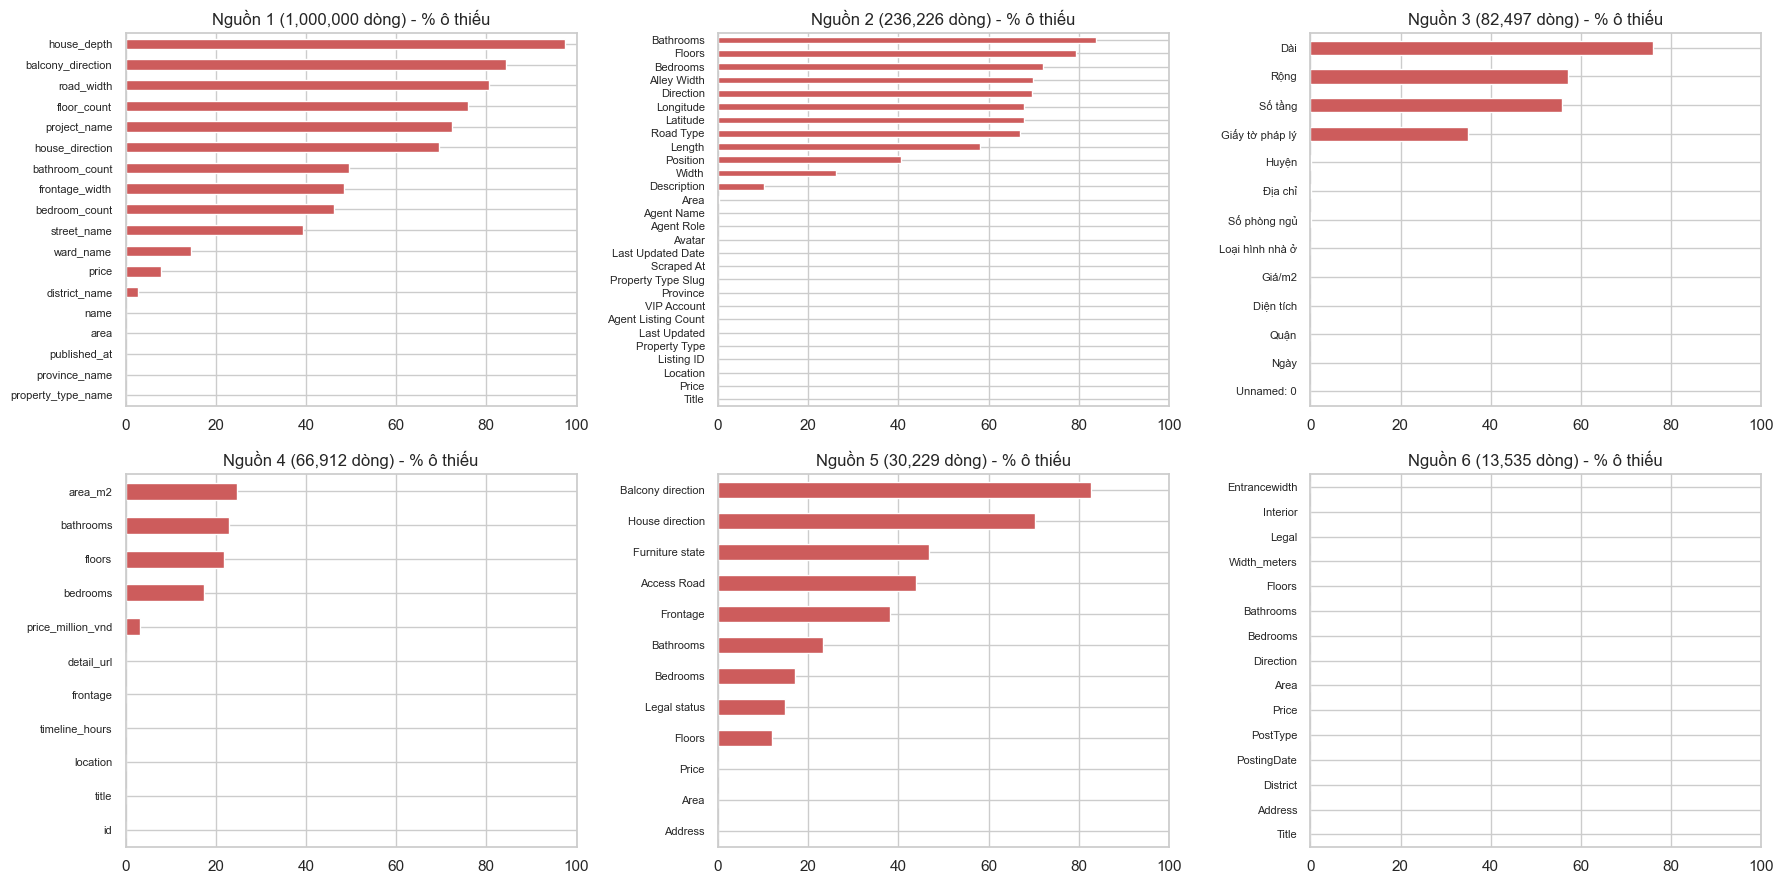

In [9]:
fig, ax = plt.subplots(2, 3, figsize=(18, 9))
for a, (k, d) in zip(ax.ravel(), du_lieu.items()):
    (d.isna().mean() * 100).sort_values().plot(kind='barh', ax=a, color='indianred')
    a.set_title(f'Nguồn {k} ({len(d):,} dòng) - % ô thiếu')
    a.set_xlim(0, 100)
    a.tick_params(axis='y', labelsize=8)
plt.tight_layout()
plt.show()

**Nhận xét:** 6 nguồn khác nhau về cấu trúc cột, đơn vị giá (VNĐ, triệu, tỷ, triệu/m²), định dạng số (dấu phẩy thập phân, chữ lẫn số, số 0 thay ô trống), cách ghi địa danh (có/không tiền tố, tỉnh cũ/tỉnh mới) và đều có trùng lặp, giá trị vô lý, thiếu dữ liệu nặng. Notebook 02 sẽ đưa tất cả về một cấu trúc chung.